# 00 Network data
Part 1 of the brief: read, validate and characterise the four instances (NYT, HAN, FOS, PES) before any algorithm runs.

File format (one file per instance in `data/`): a `V E` header, then `[NODES]` with `id x y source_flag`, `[EDGES]` with `u v capacity`, `[OFFICE]` with the id of the sampling office (task 6) and `[NEW]` with `x y capacity` for nodes to insert (task 7).

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx
import water
from water import graph, plot

plot.setup()
nets = water.load_all()

## Validation
`water.io.load` checks every record and logs what it finds instead of failing. Rules: malformed or non-numeric records, non-finite coordinates, pipes to unknown nodes, self-loops and non-positive capacities are dropped; a repeated pipe (same unordered pair) is kept once; non-contiguous ids are handled by mapping ids to matrix indices; the header counts are compared with what was loaded; `[NEW]` points far outside the network (bounding box plus a 50% margin) are rejected as outliers.

In [2]:
for name, net in nets.items():
    print(name)
    for msg in net.issues or ['no issues']:
        print('  ', msg)

# how far the rejected nyt point lies outside nyt, in network widths
import re
x0, x1, _, _ = nets['NYT'].bbox()
rx = float(re.search(r'new node \(([-\d.]+),', next(m for m in nets['NYT'].issues if 'new node' in m)).group(1))
print(f'NYT rejected point lies {(rx - x1) / (x1 - x0):.1f} network widths east of the eastern edge of NYT')

NYT
   line 49: new node (6478, 3050) lies outside the network bounding box (+50% margin), rejected as an outlier
HAN
   no issues
FOS
   no issues
PES
   line 102: pipe 30-28 repeats an earlier record with same capacity, treated as one pipe (first record kept)
   node ids are not contiguous (18 gaps, e.g. [16, 63, 64, 66, 67]); handled by mapping ids to indices
   header declares V=71, E=99; loaded V=71, E=98
NYT rejected point lies 4.6 network widths east of the eastern edge of NYT


Two findings matter. PES lists pipe 28-30 twice (once as `28 30`, once as `30 28`, same capacity), so the file declares 99 pipes but the network has 98; counting it twice would double that pipe's capacity in task 5. NYT's second `[NEW]` point (6478, 3050) lies 4.6 network widths east of the eastern edge of NYT and is identical to HAN's second `[NEW]` entry, so it is a copy error and is not inserted in task 7. No coordinate, capacity or flag is missing or invalid in any file.

## Characterisation

In [3]:
rows = []
for name, net in nets.items():
    adj = graph.adjacency_list(net)
    deg = Counter(len(adj[u]) for u in adj)
    comps = graph.components(adj)
    V, E = len(net.coords), len(net.pipes)
    caps = sorted({c for *_, c in net.pipes})
    rows.append([name, V, E, len(net.sources), V - len(net.sources), len(comps), E - V + 1,
                 deg[1], max(deg), len(caps), net.office])
    print(f'{name}: V={V} E={E} sources={net.sources} non-source={V - len(net.sources)} '
          f'office={net.office} components={len(comps)} independent loops (E-V+1)={E - V + 1}')
    print(f'   degree histogram {dict(sorted(deg.items()))}, '
          f'leaves {[u for u in adj if len(adj[u]) == 1]}')
    print(f'   capacities: {len(caps)} distinct values in [{caps[0]:g}, {caps[-1]:g}]; '
          f'new nodes accepted: {len(net.new)}')

    # cross-check connectivity with networkx
    G = nx.Graph(); G.add_nodes_from(net.coords); G.add_edges_from(p[:2] for p in net.pipes)
    assert nx.number_connected_components(G) == len(comps) == 1

plot.table('datasets', rows,
           ['Inst.', '$|V|$', '$|E|$', 'Src.', 'Non-src.', 'Comp.', 'Loops', 'Leaves', 'Max deg.', 'Caps.', 'Office'],
           ['{}', '{}', '{}', '{}', '{}', '{}', '{}', '{}', '{}', '{}', '{}'])

NYT: V=20 E=21 sources=[17, 19] non-source=18 office=5 components=1 independent loops (E-V+1)=2
   degree histogram {1: 2, 2: 15, 3: 2, 4: 1}, leaves [17, 19]
   capacities: 9 distinct values in [61, 207]; new nodes accepted: 2
HAN: V=32 E=34 sources=[13, 1] non-source=30 office=29 components=1 independent loops (E-V+1)=3
   degree histogram {1: 3, 2: 23, 3: 5, 4: 1}, leaves [13, 22, 1]
   capacities: 2 distinct values in [16, 18]; new nodes accepted: 3
FOS: V=37 E=58 sources=[7, 37] non-source=35 office=4 components=1 independent loops (E-V+1)=22
   degree histogram {1: 1, 3: 29, 4: 7}, leaves [37]
   capacities: 22 distinct values in [17, 232.2]; new nodes accepted: 2
PES: V=71 E=98 sources=[1, 7] non-source=69 office=51 components=1 independent loops (E-V+1)=28
   degree histogram {1: 5, 2: 14, 3: 46, 4: 5, 5: 1}, leaves [7, 10, 36, 87, 15]
   capacities: 14 distinct values in [101, 401]; new nodes accepted: 2


Node attributes: id, x, y and a source flag; one node per instance is also tagged as the office. Edge attributes: the two endpoint ids and one number that the challenge slides call the pipe capacity (their figures label it as the diameter). No instance stores pipe length, so it is computed from coordinates in task 2.

Structure: every instance is connected and has exactly two sources. NYT and HAN are almost trees (2 and 3 independent loops), so most nodes have a single route to a source; FOS and PES are meshed (22 and 28 loops), so alternative routes exist. Six of the eight sources are leaves (both in NYT and HAN, 37 in FOS, 7 in PES), so a single pipe connects each of them to the rest of the network; this reappears as the bottleneck in task 5. PES has very short pipes (under 5 units) next to pipes over 1500 units, so its geometry is far from uniform.

## Computational representation
`water.io.Network` holds the raw data: `coords` (dict id to (x, y)), `sources`, `pipes` (list of `(u, v, capacity)`), `office` and `new`. Algorithms work on structures derived from it in `water.graph`: an adjacency list (dict id to list of `(neighbour, length)`, used by traversals, Dijkstra and flow) and an adjacency matrix (NumPy array indexed through an id-to-index map, used by Floyd-Warshall). Task 1 compares the two.

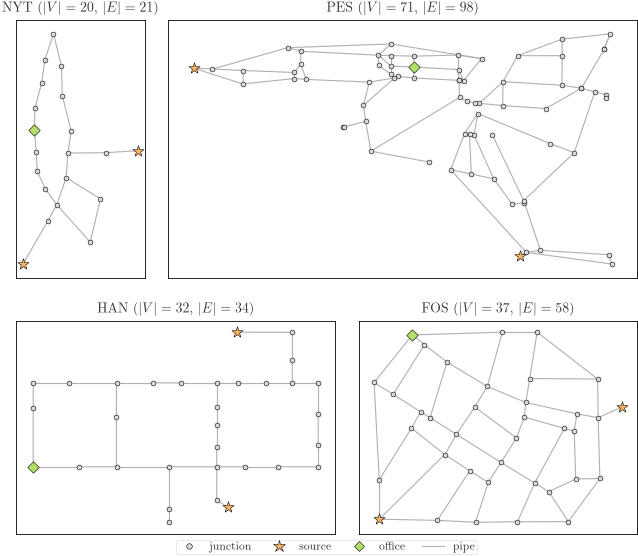

In [4]:
fig, axes = plot.instance_axes(nets)
for name, ax in axes.items():
    net = nets[name]
    plot.pipes(ax, net)
    plot.nodes(ax, net, [u for u in net.coords if u not in net.sources])
    plot.sources(ax, net)
    plot.office(ax, net)
    plot.frame(ax, f'{name} ($|V|={len(net.coords)}$, $|E|={len(net.pipes)}$)')
h = [plt.Line2D([], [], ls='', marker='o', mfc=plot.NODE, mec='k', mew=0.4, ms=4, label='junction'),
     plt.Line2D([], [], ls='', marker='*', mfc=plot.SOURCE, mec='k', mew=0.4, ms=9, label='source'),
     plt.Line2D([], [], ls='', marker='D', mfc=plot.OFFICE, mec='k', mew=0.4, ms=5, label='office'),
     plt.Line2D([], [], color=plot.GRID, lw=0.8, label='pipe')]
fig.legend(handles=h, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=4)
plot.save(fig, 'networks')
plt.show()